In [ ]:
!pip install -q torchmetrics[image]

import os
import time
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from torchmetrics.image.fid import FrechetInceptionDistance
import matplotlib.pyplot as plt

def set_seed(seed=42):
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.makedirs("results", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

# Transformasi ke [-1, 1] untuk GAN, DCGAN, dan DDPM
transform_norm = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

full_train_data = datasets.FashionMNIST(root="./data", train=True, download=True, transform=transform_norm)
official_test_data = datasets.FashionMNIST(root="./data", train=False, download=True, transform=transform_norm)

full_dataset = torch.utils.data.ConcatDataset([full_train_data, official_test_data])
train_size = int(0.8 * len(full_dataset))
val_size = int(0.1 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = random_split(
    full_dataset, [train_size, val_size, test_size], generator=generator
)

BATCH_SIZE = 128
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

def denorm(x):
    return torch.clamp((x + 1.0) / 2.0, 0.0, 1.0)

print(f"Setup Notebook 3 selesai pada {device}.")

100%|██████████| 26.4M/26.4M [00:01<00:00, 13.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.78MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 12.1MB/s]

Setup Notebook 3 selesai pada cuda.


In [ ]:
# --- 1. VANILLA GAN (Berbasis Fully-Connected / MLP) ---
class VanillaGenerator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 784),
            nn.Tanh()
        )
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class VanillaDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(256, 1)
        )
    def forward(self, x):
        return self.net(x.view(-1, 784))


# --- 2. DCGAN (Konvolusional Penuh sesuai Prinsip Radford et al.) ---
class DCGANGenerator(nn.Module):
    def __init__(self, z_dim=100):
        super().__init__()
        # 100 -> 256x7x7 -> 128x14x14 -> 1x28x28
        self.fc = nn.Sequential(
            nn.Linear(z_dim, 256 * 7 * 7, bias=False),
            nn.BatchNorm1d(256 * 7 * 7),
            nn.ReLU(True)
        )
        self.conv_blocks = nn.Sequential(
            nn.ConvTranspose2d(256, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 1, kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()
        )
    def forward(self, z):
        h = self.fc(z).view(-1, 256, 7, 7)
        return self.conv_blocks(h)

class DCGANDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        # 1x28x28 -> 64x14x14 -> 128x7x7 -> 1
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=4, stride=2, padding=1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1)
        )
    def forward(self, x):
        return self.net(x)

def weights_init_dcgan(m):
    classname = m.__class__.__name__
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)


# --- 3. DDPM (Denoising Diffusion Probabilistic Model dengan Time-Conditioned U-Net) ---
class SinusoidalPosEmb(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim
    def forward(self, t):
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=t.device) * -emb)
        emb = t[:, None].float() * emb[None, :]
        return torch.cat((emb.sin(), emb.cos()), dim=-1)

class SimpleUNetDDPM(nn.Module):
    def __init__(self, time_dim=64):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalPosEmb(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.GELU()
        )
        # Encoder
        self.enc1 = nn.Sequential(nn.Conv2d(1, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.GELU())
        self.down1 = nn.Conv2d(64, 64, 4, stride=2, padding=1) # 14x14
        self.enc2 = nn.Sequential(nn.Conv2d(64, 128, 3, padding=1), nn.GroupNorm(8, 128), nn.GELU())
        self.down2 = nn.Conv2d(128, 128, 4, stride=2, padding=1) # 7x7

        # Bottleneck + Time projection
        self.time_proj = nn.Linear(time_dim, 128)
        self.bot = nn.Sequential(nn.Conv2d(128, 128, 3, padding=1), nn.GroupNorm(8, 128), nn.GELU())

        # Decoder
        self.up1 = nn.ConvTranspose2d(128, 128, 4, stride=2, padding=1) # 14x14
        self.dec1 = nn.Sequential(nn.Conv2d(256, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.GELU())
        self.up2 = nn.ConvTranspose2d(64, 64, 4, stride=2, padding=1) # 28x28
        self.dec2 = nn.Sequential(nn.Conv2d(128, 64, 3, padding=1), nn.GroupNorm(8, 64), nn.GELU())
        self.out = nn.Conv2d(64, 1, 1)

    def forward(self, x, t):
        t_emb = self.time_mlp(t)
        h1 = self.enc1(x)
        h2 = self.enc2(self.down1(h1))
        h_bot = self.down2(h2) + self.time_proj(t_emb)[:, :, None, None]
        h_bot = self.bot(h_bot)
        u1 = self.dec1(torch.cat([self.up1(h_bot), h2], dim=1))
        u2 = self.dec2(torch.cat([self.up2(u1), h1], dim=1))
        return self.out(u2)

class DDPMManager:
    def __init__(self, model, T=300, beta_start=1e-4, beta_end=0.02, device="cuda"):
        self.model = model
        self.T = T
        self.device = device
        self.betas = torch.linspace(beta_start, beta_end, T, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_hat = torch.cumprod(self.alphas, dim=0)

    def forward_diffusion(self, x0, t):
        noise = torch.randn_like(x0)
        sqrt_alpha_hat = torch.sqrt(self.alpha_hat[t])[:, None, None, None]
        sqrt_one_minus = torch.sqrt(1.0 - self.alpha_hat[t])[:, None, None, None]
        xt = sqrt_alpha_hat * x0 + sqrt_one_minus * noise
        return xt, noise

    @torch.no_grad()
    def sample(self, n_samples, return_trajectory=False):
        self.model.eval()
        x = torch.randn(n_samples, 1, 28, 28, device=self.device)
        trajectory = [denorm(x.clone()).cpu()] if return_trajectory else []
        capture_steps = set(np.linspace(self.T - 1, 0, 8, dtype=int))

        for t_idx in reversed(range(self.T)):
            t_tensor = torch.full((n_samples,), t_idx, device=self.device, dtype=torch.long)
            pred_noise = self.model(x, t_tensor)
            alpha = self.alphas[t_idx]
            alpha_hat = self.alpha_hat[t_idx]
            beta = self.betas[t_idx]

            z = torch.randn_like(x) if t_idx > 0 else torch.zeros_like(x)
            x = (1.0 / torch.sqrt(alpha)) * (x - ((1.0 - alpha) / torch.sqrt(1.0 - alpha_hat)) * pred_noise) + torch.sqrt(beta) * z
            if return_trajectory and t_idx in capture_steps:
                trajectory.append(denorm(x.clone()).cpu())
        return (denorm(x), trajectory) if return_trajectory else denorm(x)

In [ ]:
EPOCHS_GAN = 25
Z_DIM = 100
criterion_bce = nn.BCEWithLogitsLoss()
gan_history = {"VGAN_G": [], "VGAN_D": [], "DCGAN_G": [], "DCGAN_D": [], "DDPM": []}
train_times_part3 = {}

# --- A. Training Vanilla GAN ---
v_gen = VanillaGenerator(Z_DIM).to(device)
v_disc = VanillaDiscriminator().to(device)
opt_vg = torch.optim.Adam(v_gen.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_vd = torch.optim.Adam(v_disc.parameters(), lr=2e-4, betas=(0.5, 0.999))

print("=== Training Vanilla GAN (MLP) ===")
durations = []
for epoch in range(1, EPOCHS_GAN + 1):
    t0 = time.time()
    v_gen.train(); v_disc.train()
    g_loss_ep, d_loss_ep = 0.0, 0.0
    for real_x, _ in train_loader:
        real_x = real_x.to(device)
        bs = real_x.size(0)
        real_lbl = torch.ones(bs, 1, device=device)
        fake_lbl = torch.zeros(bs, 1, device=device)

        # Update Discriminator
        z = torch.randn(bs, Z_DIM, device=device)
        fake_x = v_gen(z).detach()
        d_loss = criterion_bce(v_disc(real_x), real_lbl) + criterion_bce(v_disc(fake_x), fake_lbl)
        opt_vd.zero_grad(); d_loss.backward(); opt_vd.step()

        # Update Generator
        z = torch.randn(bs, Z_DIM, device=device)
        g_loss = criterion_bce(v_disc(v_gen(z)), real_lbl)
        opt_vg.zero_grad(); g_loss.backward(); opt_vg.step()

        d_loss_ep += d_loss.item(); g_loss_ep += g_loss.item()
    durations.append(time.time() - t0)
    gan_history["VGAN_D"].append(d_loss_ep / len(train_loader))
    gan_history["VGAN_G"].append(g_loss_ep / len(train_loader))
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | D_Loss: {gan_history['VGAN_D'][-1]:.4f} | G_Loss: {gan_history['VGAN_G'][-1]:.4f}")
train_times_part3["Vanilla GAN"] = np.mean(durations)

# --- B. Training DCGAN ---
dc_gen = DCGANGenerator(Z_DIM).to(device)
dc_disc = DCGANDiscriminator().to(device)
dc_gen.apply(weights_init_dcgan); dc_disc.apply(weights_init_dcgan)
opt_dcg = torch.optim.Adam(dc_gen.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_dcd = torch.optim.Adam(dc_disc.parameters(), lr=2e-4, betas=(0.5, 0.999))

print("\n=== Training DCGAN ===")
durations = []
for epoch in range(1, EPOCHS_GAN + 1):
    t0 = time.time()
    dc_gen.train(); dc_disc.train()
    g_loss_ep, d_loss_ep = 0.0, 0.0
    for real_x, _ in train_loader:
        real_x = real_x.to(device)
        bs = real_x.size(0)
        real_lbl = torch.ones(bs, 1, device=device)
        fake_lbl = torch.zeros(bs, 1, device=device)

        z = torch.randn(bs, Z_DIM, device=device)
        fake_x = dc_gen(z).detach()
        d_loss = criterion_bce(dc_disc(real_x), real_lbl) + criterion_bce(dc_disc(fake_x), fake_lbl)
        opt_dcd.zero_grad(); d_loss.backward(); opt_dcd.step()

        z = torch.randn(bs, Z_DIM, device=device)
        g_loss = criterion_bce(dc_disc(dc_gen(z)), real_lbl)
        opt_dcg.zero_grad(); g_loss.backward(); opt_dcg.step()

        d_loss_ep += d_loss.item(); g_loss_ep += g_loss.item()
    durations.append(time.time() - t0)
    gan_history["DCGAN_D"].append(d_loss_ep / len(train_loader))
    gan_history["DCGAN_G"].append(g_loss_ep / len(train_loader))
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | D_Loss: {gan_history['DCGAN_D'][-1]:.4f} | G_Loss: {gan_history['DCGAN_G'][-1]:.4f}")
train_times_part3["DCGAN"] = np.mean(durations)

=== Training Vanilla GAN (MLP) ===
Epoch 05 | D_Loss: 0.7507 | G_Loss: 2.0605
Epoch 10 | D_Loss: 0.9428 | G_Loss: 1.5576
Epoch 15 | D_Loss: 1.0572 | G_Loss: 1.3016
Epoch 20 | D_Loss: 1.0914 | G_Loss: 1.2266
Epoch 25 | D_Loss: 1.1309 | G_Loss: 1.1560

=== Training DCGAN ===
Epoch 05 | D_Loss: 0.6567 | G_Loss: 1.7368
Epoch 10 | D_Loss: 0.7609 | G_Loss: 1.6007
Epoch 15 | D_Loss: 0.8443 | G_Loss: 1.5318
Epoch 20 | D_Loss: 0.8637 | G_Loss: 1.4966
Epoch 25 | D_Loss: 0.8780 | G_Loss: 1.4815


In [ ]:
EPOCHS_DDPM = 20
unet_ddpm = SimpleUNetDDPM().to(device)
ddpm = DDPMManager(unet_ddpm, T=300, device=device)
opt_ddpm = torch.optim.Adam(unet_ddpm.parameters(), lr=2e-4)

print("\n=== Training DDPM (Noise Prediction MSE) ===")
durations = []
for epoch in range(1, EPOCHS_DDPM + 1):
    t0 = time.time()
    unet_ddpm.train()
    ep_loss = 0.0
    for x0, _ in train_loader:
        x0 = x0.to(device)
        t = torch.randint(0, ddpm.T, (x0.size(0),), device=device).long()
        xt, noise = ddpm.forward_diffusion(x0, t)
        pred_noise = unet_ddpm(xt, t)
        loss = F.mse_loss(pred_noise, noise)
        opt_ddpm.zero_grad(); loss.backward(); opt_ddpm.step()
        ep_loss += loss.item()
    durations.append(time.time() - t0)
    gan_history["DDPM"].append(ep_loss / len(train_loader))
    if epoch % 5 == 0:
        print(f"Epoch {epoch:02d} | Noise MSE Loss: {gan_history['DDPM'][-1]:.5f}")
train_times_part3["DDPM"] = np.mean(durations)


=== Training DDPM (Noise Prediction MSE) ===
Epoch 05 | Noise MSE Loss: 0.08827
Epoch 10 | Noise MSE Loss: 0.08187
Epoch 15 | Noise MSE Loss: 0.07867
Epoch 20 | Noise MSE Loss: 0.07694


In [ ]:
def measure_latency_64(fn_infer, runs=30):
    for _ in range(5):
        _ = fn_infer()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(runs):
        _ = fn_infer()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
    return ((time.time() - t0) / runs) * 1000.0

def compute_fid_score(gen_fn, n_samples=7000):
    fid = FrechetInceptionDistance(feature=64, normalize=True).to(device)
    with torch.no_grad():
        for x, _ in test_loader:
            x_rgb = denorm(x).repeat(1, 3, 1, 1).to(device)
            fid.update(x_rgb, real=True)
        for _ in range(0, n_samples, 128):
            fake_rgb = gen_fn(128).repeat(1, 3, 1, 1)
            fid.update(fake_rgb, real=False)
    return fid.compute().item()

v_gen.eval(); dc_gen.eval(); unet_ddpm.eval()

# 1. Latency Batch 64
lat_vgan = measure_latency_64(lambda: v_gen(torch.randn(64, Z_DIM, device=device)), runs=50)
lat_dcgan = measure_latency_64(lambda: dc_gen(torch.randn(64, Z_DIM, device=device)), runs=50)
# DDPM multi-step denoising membutuhkan 300 pass sehingga runs=3 sudah akurat
lat_ddpm = measure_latency_64(lambda: ddpm.sample(64), runs=3)

# 2. FID Score
print("Menghitung FID Score (tunggu ~1 menit untuk sampling DDPM)...")
fid_vgan = compute_fid_score(lambda n: denorm(v_gen(torch.randn(n, Z_DIM, device=device))))
fid_dcgan = compute_fid_score(lambda n: denorm(dc_gen(torch.randn(n, Z_DIM, device=device))))
fid_ddpm = compute_fid_score(lambda n: ddpm.sample(n))

print("\n=== HASIL EVALUASI TEST SET (BAGIAN IV LAPORAN) ===")
print(f"[Vanilla GAN] Train/Epoch: {train_times_part3['Vanilla GAN']:.2f}s | Latency(64): {lat_vgan:.3f}ms | FID: {fid_vgan:.2f}")
print(f"[DCGAN]       Train/Epoch: {train_times_part3['DCGAN']:.2f}s | Latency(64): {lat_dcgan:.3f}ms | FID: {fid_dcgan:.2f}")
print(f"[DDPM]        Train/Epoch: {train_times_part3['DDPM']:.2f}s | Latency(64): {lat_ddpm:.3f}ms | FID: {fid_ddpm:.2f}")

Menghitung FID Score (tunggu ~1 menit untuk sampling DDPM)...


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 116MB/s]



=== HASIL EVALUASI TEST SET (BAGIAN IV LAPORAN) ===
[Vanilla GAN] Train/Epoch: 13.82s | Latency(64): 0.206ms | FID: 0.43
[DCGAN]       Train/Epoch: 21.21s | Latency(64): 2.160ms | FID: 0.01
[DDPM]        Train/Epoch: 28.52s | Latency(64): 2334.791ms | FID: 0.94


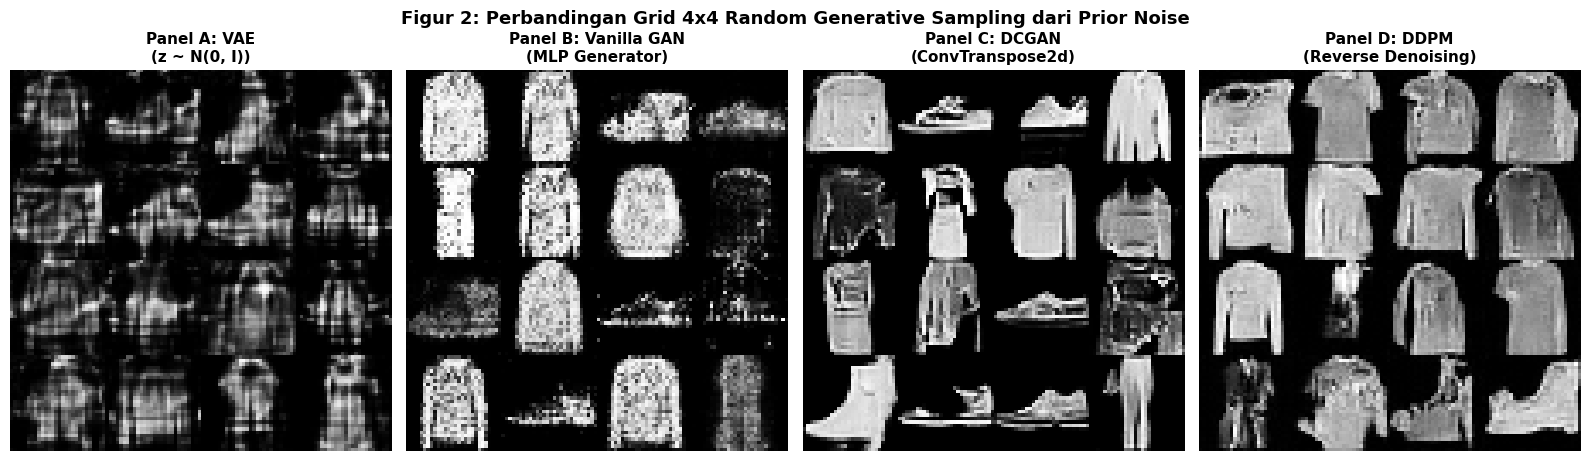

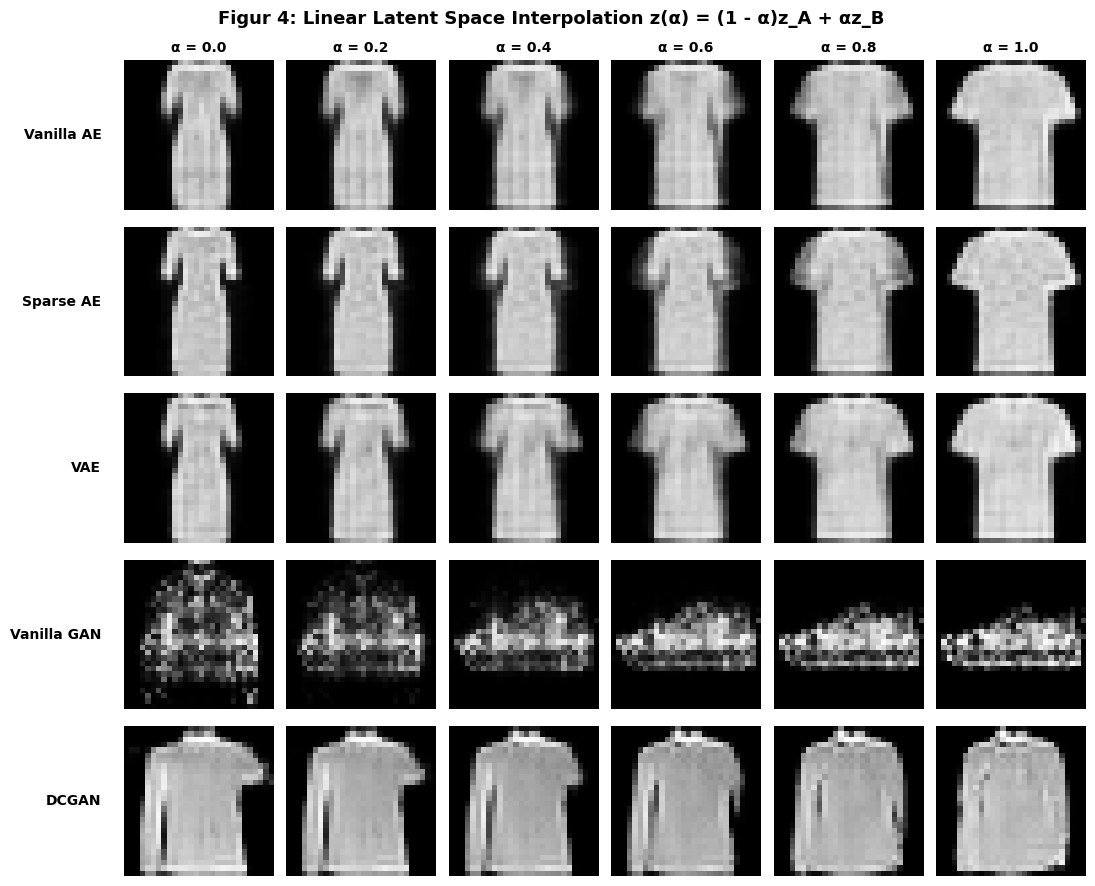

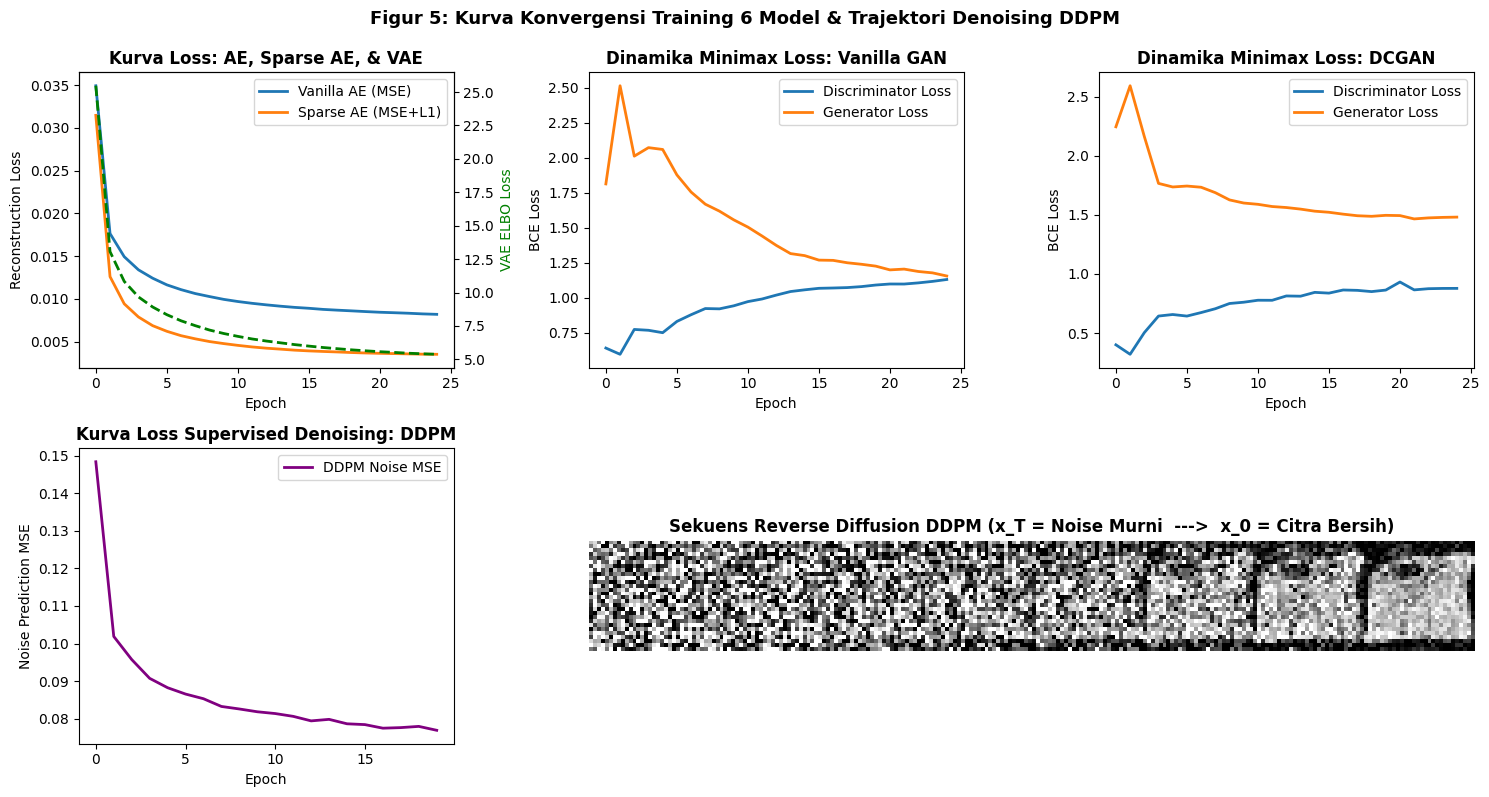

In [ ]:
# --- Muat ulang model AE/VAE dari Notebook 2 untuk grafik gabungan ---
class VanillaAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, latent_dim), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(latent_dim, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid())
    def encode(self, x): return self.encoder(x.view(-1, 784))
    def decode(self, z): return self.decoder(z).view(-1, 1, 28, 28)

class SparseAE(nn.Module):
    def __init__(self, hidden_dim=256):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(784, hidden_dim), nn.ReLU())
        self.decoder = nn.Sequential(nn.Linear(hidden_dim, 784), nn.Sigmoid())
    def encode(self, x): return self.encoder(x.view(-1, 784))
    def decode(self, h): return self.decoder(h).view(-1, 1, 28, 28)

class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)
        self.fc_dec1 = nn.Linear(latent_dim, 256)
        self.fc_dec2 = nn.Linear(256, 784)
    def encode(self, x):
        h = F.relu(self.fc1(x.view(-1, 784)))
        return self.fc_mu(h), self.fc_logvar(h)
    def decode(self, z):
        return torch.sigmoid(self.fc_dec2(F.relu(self.fc_dec1(z)))).view(-1, 1, 28, 28)

vanilla_ae = VanillaAE(64).to(device)
sparse_ae = SparseAE(256).to(device)
vae_model = VAE(64).to(device)

has_ae_ckpt = os.path.exists("checkpoints/vae.pth")
if has_ae_ckpt:
    vanilla_ae.load_state_dict(torch.load("checkpoints/vanilla_ae.pth", map_location=device))
    sparse_ae.load_state_dict(torch.load("checkpoints/sparse_ae.pth", map_location=device))
    vae_model.load_state_dict(torch.load("checkpoints/vae.pth", map_location=device))
    vanilla_ae.eval(); sparse_ae.eval(); vae_model.eval()
else:
    print("PERINGATAN: Checkpoint Notebook 2 tidak ditemukan di checkpoints/. Pastikan file sudah diunggah!")

# =========================================================================
# FIGUR 2: Grid 4x4 Random Generative Sampling (VAE, Vanilla GAN, DCGAN, DDPM)
# =========================================================================
with torch.no_grad():
    samples_vae = vae_model.decode(torch.randn(16, 64, device=device)).cpu()
    samples_vgan = denorm(v_gen(torch.randn(16, Z_DIM, device=device))).cpu()
    samples_dcgan = denorm(dc_gen(torch.randn(16, Z_DIM, device=device))).cpu()
    samples_ddpm, ddpm_traj = ddpm.sample(16, return_trajectory=True)
    samples_ddpm = samples_ddpm.cpu()

fig2, subfigs = plt.subplots(1, 4, figsize=(16, 4.5))
panels = [
    ("Panel A: VAE\n(z ~ N(0, I))", samples_vae),
    ("Panel B: Vanilla GAN\n(MLP Generator)", samples_vgan),
    ("Panel C: DCGAN\n(ConvTranspose2d)", samples_dcgan),
    ("Panel D: DDPM\n(Reverse Denoising)", samples_ddpm)
]

for ax_main, (title, imgs) in zip(subfigs, panels):
    grid = np.zeros((28 * 4, 28 * 4))
    for idx in range(16):
        r, c = idx // 4, idx % 4
        grid[r*28:(r+1)*28, c*28:(c+1)*28] = imgs[idx, 0].numpy()
    ax_main.imshow(grid, cmap="gray", vmin=0, vmax=1)
    ax_main.set_title(title, fontsize=11, fontweight="bold")
    ax_main.axis("off")

plt.suptitle("Figur 2: Perbandingan Grid 4x4 Random Generative Sampling dari Prior Noise", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("results/figur_2_sampling.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================================
# FIGUR 4: Linear Latent Space Interpolation (alpha = 0.0, 0.2, ..., 1.0)
# =========================================================================
# Ambil 2 citra dengan kelas berbeda dari test_loader (misal T-shirt vs Sneaker/Boot)
x_batch, y_batch = next(iter(test_loader))
idx_a = 0
idx_b = next(i for i in range(1, len(y_batch)) if y_batch[i] != y_batch[idx_a])
img_a = denorm(x_batch[idx_a:idx_a+1]).to(device)
img_b = denorm(x_batch[idx_b:idx_b+1]).to(device)

alphas = [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
interp_rows = []
interp_labels = ["Vanilla AE", "Sparse AE", "VAE", "Vanilla GAN", "DCGAN"]

with torch.no_grad():
    # AE, Sparse AE, VAE interpolasi antar citra uji ter-encode
    za_vae, zb_vae = vanilla_ae.encode(img_a), vanilla_ae.encode(img_b)
    za_sae, zb_sae = sparse_ae.encode(img_a), sparse_ae.encode(img_b)
    za_var, _ = vae_model.encode(img_a)
    zb_var, _ = vae_model.encode(img_b)

    # GAN & DCGAN interpolasi antar dua titik random latent z_A dan z_B
    z_gan_a, z_gan_b = torch.randn(1, Z_DIM, device=device), torch.randn(1, Z_DIM, device=device)

    row_vae, row_sae, row_var, row_vgan, row_dcgan = [], [], [], [], []
    for a in alphas:
        row_vae.append(vanilla_ae.decode((1 - a) * za_vae + a * zb_vae).cpu())
        row_sae.append(sparse_ae.decode((1 - a) * za_sae + a * zb_sae).cpu())
        row_var.append(vae_model.decode((1 - a) * za_var + a * zb_var).cpu())
        z_interp = (1 - a) * z_gan_a + a * z_gan_b
        row_vgan.append(denorm(v_gen(z_interp)).cpu())
        row_dcgan.append(denorm(dc_gen(z_interp)).cpu())
    interp_rows = [row_vae, row_sae, row_var, row_vgan, row_dcgan]

fig4, axes4 = plt.subplots(5, 6, figsize=(11, 9))
for r_idx, (row_imgs, m_name) in enumerate(zip(interp_rows, interp_labels)):
    for c_idx, a in enumerate(alphas):
        ax = axes4[r_idx, c_idx]
        ax.imshow(row_imgs[c_idx][0, 0], cmap="gray", vmin=0, vmax=1)
        ax.axis("off")
        if r_idx == 0:
            ax.set_title(f"α = {a:.1f}", fontsize=10, fontweight="bold")
    axes4[r_idx, 0].text(-0.15, 0.5, m_name, transform=axes4[r_idx, 0].transAxes,
                         fontsize=10, fontweight="bold", va="center", ha="right")

plt.suptitle("Figur 4: Linear Latent Space Interpolation z(α) = (1 - α)z_A + αz_B", fontsize=13, fontweight="bold", y=0.98)
plt.tight_layout()
plt.savefig("results/figur_4_interpolasi.png", dpi=300, bbox_inches="tight")
plt.show()

# =========================================================================
# FIGUR 5: Training Loss Curves (6 Model) + DDPM Reverse Diffusion Trajectory
# =========================================================================
fig5 = plt.figure(figsize=(15, 8))
gs = fig5.add_gridspec(2, 3)

# Plot 1: AE & VAE Loss
ax1 = fig5.add_subplot(gs[0, 0])
if os.path.exists("checkpoints/ae_loss_history.npy"):
    ae_hist = np.load("checkpoints/ae_loss_history.npy", allow_pickle=True).item()
    ax1.plot(ae_hist["Vanilla AE"], label="Vanilla AE (MSE)", lw=2)
    ax1.plot(ae_hist["Sparse AE"], label="Sparse AE (MSE+L1)", lw=2)
    ax1_twin = ax1.twinx()
    ax1_twin.plot(ae_hist["VAE"], color="green", linestyle="--", label="VAE (ELBO)", lw=2)
    ax1_twin.set_ylabel("VAE ELBO Loss", color="green")
ax1.set_title("Kurva Loss: AE, Sparse AE, & VAE", fontweight="bold")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Reconstruction Loss")
ax1.legend(loc="upper right")

# Plot 2: Vanilla GAN G vs D Loss
ax2 = fig5.add_subplot(gs[0, 1])
ax2.plot(gan_history["VGAN_D"], label="Discriminator Loss", lw=2)
ax2.plot(gan_history["VGAN_G"], label="Generator Loss", lw=2)
ax2.set_title("Dinamika Minimax Loss: Vanilla GAN", fontweight="bold")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("BCE Loss")
ax2.legend()

# Plot 3: DCGAN G vs D Loss
ax3 = fig5.add_subplot(gs[0, 2])
ax3.plot(gan_history["DCGAN_D"], label="Discriminator Loss", lw=2)
ax3.plot(gan_history["DCGAN_G"], label="Generator Loss", lw=2)
ax3.set_title("Dinamika Minimax Loss: DCGAN", fontweight="bold")
ax3.set_xlabel("Epoch"); ax3.set_ylabel("BCE Loss")
ax3.legend()

# Plot 4: DDPM Noise Prediction Loss
ax4 = fig5.add_subplot(gs[1, 0])
ax4.plot(gan_history["DDPM"], color="purple", label="DDPM Noise MSE", lw=2)
ax4.set_title("Kurva Loss Supervised Denoising: DDPM", fontweight="bold")
ax4.set_xlabel("Epoch"); ax4.set_ylabel("Noise Prediction MSE")
ax4.legend()

# Plot 5 (Spanning 2 columns): DDPM Reverse Diffusion Trajectory (x_T -> x_0)
ax5 = fig5.add_subplot(gs[1, 1:])
n_steps_vis = min(8, len(ddpm_traj))
traj_strip = np.hstack([ddpm_traj[i][0, 0].numpy() for i in range(n_steps_vis)])
ax5.imshow(traj_strip, cmap="gray", vmin=0, vmax=1)
ax5.set_title("Sekuens Reverse Diffusion DDPM (x_T = Noise Murni  --->  x_0 = Citra Bersih)", fontweight="bold")
ax5.axis("off")

plt.suptitle("Figur 5: Kurva Konvergensi Training 6 Model & Trajektori Denoising DDPM", fontsize=13, fontweight="bold", y=0.99)
plt.tight_layout()
plt.savefig("results/figur_5_loss_ddpm.png", dpi=300, bbox_inches="tight")
plt.show()